In [2]:
import os
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Hiragino Sans'  # macOS標準日本語フォント

import importlib
# それぞれのモジュールをインポート
import data_utils
import preprocess
import feature_extraction

# 修正を反映
importlib.reload(data_utils)
importlib.reload(preprocess)
importlib.reload(feature_extraction)

# 必要な関数やクラスを再度ノートブックに取り込む
from data_utils import *
from preprocess import *
from feature_extraction import *

In [11]:
# 定数
LABEL_COUNT = 3 # ラベル数
SAMPLING_RATE = 47  # サンプリングレート

data_folder = "../data/20250922"

file_paths = [f for f in os.listdir(data_folder + "/1") if f.endswith('.txt')]

for i in range(len(file_paths)):
    print(f"{i:2}:{file_paths[i]}")

# row_data = []
# row_csi = []

# row_amp = []    # 振幅
# row_phase = []  # 位相

# # 前処理
# buttter_filtered__csi = []
# median_filtered_csi = []

# # 分割
# split_data = []
# split_csi = []
# merged_split_data = []  # [ラベル][分割後データ数][データ]
# merged_split_csi = []   # [ラベル][分割後データ数][CSI]

# # クラス数を削減
# restored_split_csi = []

 0:20250922_121949_data_2_.txt
 1:20250922_121949_data.txt


In [12]:
# row_data/row_csiにデータを格納する
row_data, row_csi = load_csi_data(LABEL_COUNT, data_folder, file_paths)

# 振幅と位相を分割
row_amp, row_phase = split_amp_phase(row_csi)

In [37]:
row_amp = row_phase

In [14]:
# row_ampのサブキャリアを制限
row_amp = row_phase

# HT-LTFのサブキャリアを抽出（66~93, 95~123）
row_amp = [
    [
        [ [v for i, v in enumerate(row[66:123], start=66) if i != 94] 
          for row in file ]
        for file in label
    ]
    for label in row_amp
]

In [38]:
print("ラベル数:      "+str(len(row_amp)))
print("ファイル数:    "+str(len(row_amp[0])))
print("レコード数:    "+str(len(row_amp[0][0])))
print("サブキャリア数: "+str(len(row_amp[0][0][0])))

print(row_amp[0][0][63])

ラベル数:      3
ファイル数:    2
レコード数:    1248
サブキャリア数: 192
[0, 0, 0, 0, 0, 0, 12, 10, 11, 11, 11, 9, 9, 9, 9, 9, 9, 9, 8, 7, 7, 7, 6, 6, 5, 5, 5, 5, 5, 4, 5, 4, 0, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 3, 4, 3, 0, 0, 0, 0, 0, 0, 0, -16, -20, -21, -11, -11, -20, -13, -15, -14, -19, -11, -12, -10, -15, -19, -11, -16, -19, -14, -9, -5, -12, -4, 2, -3, -3, -7, -2, -2, -2, -1, 6, 4, 8, 11, 9, 9, 15, 9, 11, 10, 9, 8, 8, 9, 7, 10, 5, 1, 3, 4, 6, 6, 5, -4, -2, -3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -39, -42, -42, -52, -44, -54, -52, -50, -56, -51, -60, -59, -61, -60, -64, -61, -79, -57, -70, -65, -65, -59, -58, -66, -61, -65, -55, -60, -55, -71, -50, -62, -60, -56, -63, -56, -57, -65, -62, -61, -61, -64, -72, -56, -71, -67, -61, -68, -69, -67, -65, -66, -65, -64, -74, -76, -65, 0]


In [ ]:
# 前処理：バターワースフィルタ
buttter_filtered__csi, plt_obj = butter_lowpass_filter_csi(row_amp, SAMPLING_RATE)
# plt_obj.show()

# 前処理：メディアンフィルタ
median_filtered_csi, plt_obj = median_filter_csi(row_amp)
# plt_obj.show()

In [40]:
# 500msごとに分割（各ファイルの先頭msを基準に相対時間で分割）
split_data, split_csi = split_by_interval(row_data, row_amp, interval_ms=500)

# 各ラベルごとに全ファイルの分割データを連結する
merged_split_data, merged_split_csi = merge_split_data(split_data, split_csi)

In [41]:
# split_data: [ラベル][ファイル][分割後データ数][データ]
# split_csi:  [ラベル][ファイル][分割後データ数][CSI]

merged_split_data = []
merged_split_csi = []

for label_data, label_csi in zip(split_data, split_csi):
    merged_data = []
    merged_csi = []
    for file_data, file_csi in zip(label_data, label_csi):
        merged_data.extend(file_data)
        merged_csi.extend(file_csi)
    merged_split_data.append(merged_data)
    merged_split_csi.append(merged_csi)

# merged_split_data: [ラベル][分割後データ数][データ]
# merged_split_csi:  [ラベル][分割後データ数][CSI]

In [42]:
# クラスの削減

# 使いたいラベルのインデックス
target_labels = [[0], [1], [2]]


# クラス削減（ラベルグループ化）を関数で実行
restored_split_csi = group_labels_by_indices(merged_split_csi, target_labels)

print(len(restored_split_csi[0]))
print(len(merged_split_csi[0]))

101
101


In [62]:
# 特徴量抽出と特徴量名リスト作成（13種類＋追加特徴量）
X, y, feature_names = create_feature_matrix(restored_split_csi, SAMPLING_RATE, 
                                            use_additional=False)
                                            # , feature_list=["二乗平均平方根", "標準偏差", "最大値", "最小値"])

print(f"抽出された特徴量数: {len(feature_names)}")
print("特徴量名リスト例:", feature_names)
# 統計特徴量
stat_features = extract_features_per_subcarrier(restored_split_csi[0][0])[0]
print("統計特徴量:", stat_features)

# 追加特徴量
# if(additional_features):
#     add_features = extract_additional_features_per_subcarrier(restored_split_csi[0][0], SAMPLING_RATE)[0]
#     print("追加特徴量:", add_features)

/Users/tanakakeiji/研究コード/reserch-analysis/venv/lib/python3.9/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


抽出された特徴量数: 2496
特徴量名リスト例: ['subc0_平均', 'subc0_中央値', 'subc0_標準偏差', 'subc0_最大値', 'subc0_最小値', 'subc0_上四分位値', 'subc0_下四分位値', 'subc0_四分位範囲', 'subc0_平均絶対偏差', 'subc0_尖度', 'subc0_歪度', 'subc0_自己相関', 'subc0_二乗平均平方根', 'subc1_平均', 'subc1_中央値', 'subc1_標準偏差', 'subc1_最大値', 'subc1_最小値', 'subc1_上四分位値', 'subc1_下四分位値', 'subc1_四分位範囲', 'subc1_平均絶対偏差', 'subc1_尖度', 'subc1_歪度', 'subc1_自己相関', 'subc1_二乗平均平方根', 'subc2_平均', 'subc2_中央値', 'subc2_標準偏差', 'subc2_最大値', 'subc2_最小値', 'subc2_上四分位値', 'subc2_下四分位値', 'subc2_四分位範囲', 'subc2_平均絶対偏差', 'subc2_尖度', 'subc2_歪度', 'subc2_自己相関', 'subc2_二乗平均平方根', 'subc3_平均', 'subc3_中央値', 'subc3_標準偏差', 'subc3_最大値', 'subc3_最小値', 'subc3_上四分位値', 'subc3_下四分位値', 'subc3_四分位範囲', 'subc3_平均絶対偏差', 'subc3_尖度', 'subc3_歪度', 'subc3_自己相関', 'subc3_二乗平均平方根', 'subc4_平均', 'subc4_中央値', 'subc4_標準偏差', 'subc4_最大値', 'subc4_最小値', 'subc4_上四分位値', 'subc4_下四分位値', 'subc4_四分位範囲', 'subc4_平均絶対偏差', 'subc4_尖度', 'subc4_歪度', 'subc4_自己相関', 'subc4_二乗平均平方根', 'subc5_平均', 'subc5_中央値', 'subc5_標準偏差', 'subc5_最大値', 'subc5_最小値', 'su

In [63]:
# ランダムフォレスト
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# データ分割
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# ランダムフォレストで学習・予測
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# 結果表示
print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           0      1.000     0.950     0.974        20
           1      0.957     1.000     0.978        22
           2      1.000     1.000     1.000        17

    accuracy                          0.983        59
   macro avg      0.986     0.983     0.984        59
weighted avg      0.984     0.983     0.983        59



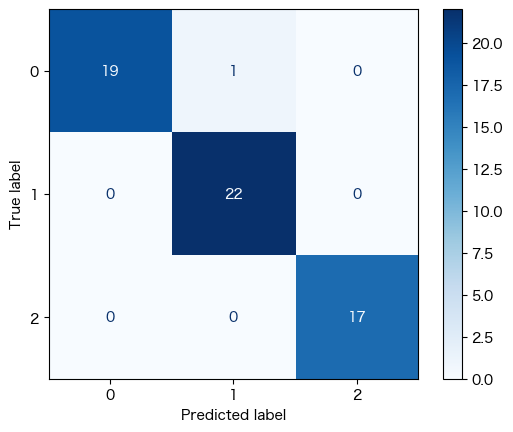

In [64]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# すでに学習・予測済み（y_test, y_predがある場合）
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.show()

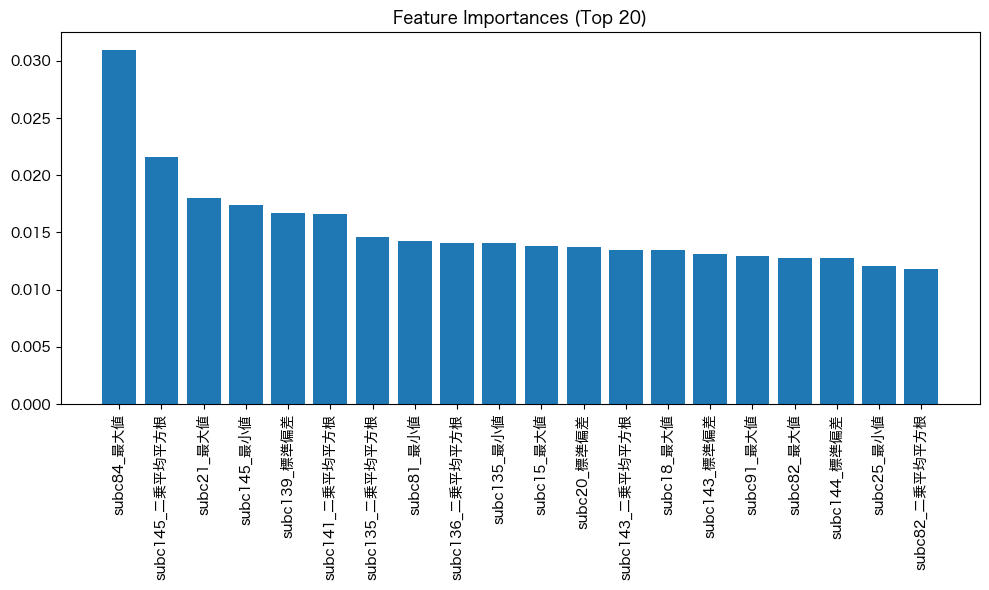

In [65]:
# 特徴量重要度の取得
importances = clf.feature_importances_
indices = np.argsort(importances)[::-1]

# 上位20特徴量を表示（必要に応じて変更）
top_n = 20
plt.figure(figsize=(10,6))

plt.title("Feature Importances (Top {})".format(top_n))
plt.bar(range(top_n), importances[indices][:top_n], align='center')
plt.xticks(range(top_n), [feature_names[i] for i in indices[:top_n]], rotation=90)
plt.tight_layout()
plt.show()

In [57]:
# 上位特徴量のみで再学習・評価
res = 0
max_acc = 0
report_str = ""

res_min = 0
min_acc = 1
report_min = ""

for i in range(len(feature_names)):
    top_n = i + 1
    selected_indices = indices[:top_n]
    X_selected = [[x[i] for i in selected_indices] for x in X]

    # データ分割
    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_selected, y, test_size=0.2, random_state=42, stratify=y)

    clf_s = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    clf_s.fit(X_train_s, y_train_s)
    y_pred_s = clf_s.predict(X_test_s)

    report = classification_report(y_test_s, y_pred_s, digits=3, output_dict=True)
    if report['accuracy'] > max_acc:
        max_acc = report['accuracy']
        res = i
        report_str = classification_report(y_test_s, y_pred_s, digits=3)
        
    if report['accuracy'] < min_acc:
        min_acc = report['accuracy']
        res_min = i
        report_min = classification_report(y_test_s, y_pred_s, digits=3)

print(f"--- 上位{res+1}特徴量のみ ---")
print(report_str)

print(f"--- 上位{res_min+1}特徴量のみ ---")
print(report_min)

KeyboardInterrupt: 

In [154]:
# RFECVで選ばれた特徴量のみ抽出
selected_indices = [i for i in range(len(feature_names)) if selector.support_[i]]
X_selected = [[x[i] for i in selected_indices] for x in X]

# 学習・評価
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.2, random_state=42, stratify=y)
clf_selected = RandomForestClassifier(n_estimators=100, random_state=42)
clf_selected.fit(X_train, y_train)
y_pred_selected = clf_selected.predict(X_test)

print(classification_report(y_test, y_pred_selected, digits=3))

NameError: name 'selector' is not defined

In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# 特徴量抽出（追加特徴量も含む）
X_np = np.array(X)

# PCAによる2次元プロット
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_np)

plt.figure(figsize=(8, 6))
for label in np.unique(y):
    plt.scatter(X_pca[y == label, 0], X_pca[y == label, 1], label=f"PCA Class {label}", alpha=0.6)
plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.title("PCAによる2次元プロット")
plt.legend()
plt.tight_layout()
plt.show()

# t-SNEによる2次元プロット
tsne = TSNE(n_components=2, random_state=42, init='pca')
X_tsne = tsne.fit_transform(X_np)

plt.figure(figsize=(8, 6))
for label in np.unique(y):
    plt.scatter(X_tsne[y == label, 0], X_tsne[y == label, 1], label=f"t-SNE Class {label}", alpha=0.6)
plt.xlabel("t-SNE1")
plt.ylabel("t-SNE2")
plt.title("t-SNEによる2次元プロット")
plt.legend()
plt.tight_layout()
plt.show()

ValueError: Input X contains NaN.
PCA does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values